# Módulo 8 — Transformada de Fourier
## Seção 8.5 — Transformada de Fourier contínua

**Objetivo.** Entender por que uma função não periódica pode ser descrita por um contínuo de frequências, deduzir transformadas elementares e interpretar espectros sem confundir uma transformada de sinal determinístico com a densidade espectral de um processo aleatório.

**Pré-requisitos:** seções 8.1–8.4; exponencial complexa; integrais definidas e impróprias; números complexos.

**Rastreabilidade.** Morettin e Toloi (2018), v. 1, cap. 13, §13.4, pp. 348–350, apresentam a decomposição harmônica **discreta**; cap. 14, §14.2, pp. 357–359, relaciona autocovariância e densidade espectral, e §14.4.1, pp. 367–369, trata da transformada **discreta**. A definição da transformada contínua de uma função e as provas abaixo são **complementação matemática elaborada para preencher o pré-requisito**; não são atribuídas literalmente ao livro.

---

### 1. Intuição e problema

Na seção 8.4 representamos uma função **periódica** por frequências múltiplas de $\omega_0=2\pi/T$. Mas um pulso isolado ou uma perturbação de duração finita não precisa se repetir. Quando o período de referência cresce, a distância entre harmônicos $\Delta\omega=2\pi/T$ diminui. Isso motiva trocar uma **soma** de componentes discretas por uma **integral** sobre todas as frequências.

O objetivo é identificar quanto de cada frequência angular $\omega$ contribui para a forma do sinal. Essa descrição é útil para filtragem, análise de pulsos e construção da DFT; não informa, sozinha, em que instante uma oscilação ocorreu.

### 2. Definição formal e convenção

Para $f\in L^1(\mathbb R)$ (isto é, $\int_{-\infty}^{\infty}|f(t)|dt<\infty$), a transformada de Fourier está bem definida por

$$\boxed{F(\omega)=\mathcal F\{f\}(\omega)=\int_{-\infty}^{\infty} f(t)e^{-i\omega t}\,dt,\quad \omega\in\mathbb R.}$$

Aqui $t$ é o tempo, $\omega$ a frequência **angular** em radianos por unidade de tempo, $i^2=-1$ e $F(\omega)$ uma amplitude **complexa**. Sua magnitude $|F(\omega)|$ mede o peso espectral nessa convenção e $\arg F(\omega)$ é a fase. A frequência em ciclos por unidade de tempo é $\nu=\omega/(2\pi)$.

Sob condições adicionais (por exemplo, $f,F\in L^1$, com interpretação nos pontos de continuidade), vale a fórmula de inversão

$$\boxed{f(t)=\frac{1}{2\pi}\int_{-\infty}^{\infty}F(\omega)e^{i\omega t}\,d\omega.}$$

A inversão também possui interpretações mais amplas em $L^2$ e em distribuições, que exigem fundamentação adicional. **Não** afirmamos que a integral inversa converge pontualmente para toda função integrável.

**Atenção às convenções:** outras fontes distribuem os fatores $2\pi$ de outra forma ou usam $e^{+i\omega t}$ na transformação direta. Sempre informe a convenção antes de comparar fórmulas.

### 3. De onde surge a integral? Ponte conceitual com Fourier em intervalos

Considere uma função restrita a $[-T/2,T/2]$, prolongada periodicamente com período $T$. Seus coeficientes complexos são

$$c_k=\frac1T\int_{-T/2}^{T/2}f(t)e^{-ik\omega_0t}\,dt,\qquad\omega_0=\frac{2\pi}{T}.$$

Sua soma parcial formal é $\sum_k c_k e^{ik\omega_0t}$. Escrevendo $\Delta\omega=2\pi/T$,

$$c_k=\frac{\Delta\omega}{2\pi}\int_{-T/2}^{T/2}f(t)e^{-i(k\Delta\omega)t}\,dt.$$

Logo a reconstrução tem a forma

$$\sum_k\frac{\Delta\omega}{2\pi}F_T(k\Delta\omega)e^{ik\Delta\omega t},\qquad F_T(\omega)=\int_{-T/2}^{T/2}f(t)e^{-i\omega t}\,dt.$$

Para funções suficientemente regulares e decrescentes, quando $T\to\infty$ temos $\Delta\omega\to0$, $F_T\to F$ de modo apropriado e a soma se aproxima de uma integral de Riemann. **Trata-se de uma motivação**, não de uma demonstração geral da inversão para qualquer função.

### 4. Exemplo completo: pulso retangular

Escolha $a>0$ e

$$f(t)=\begin{cases}1,& |t|\le a,\\0,&|t|>a.\end{cases}$$

O cálculo é direto:

$$\begin{aligned}
F(\omega)&=\int_{-a}^{a}e^{-i\omega t}\,dt\\
&=\left[\frac{e^{-i\omega t}}{-i\omega}\right]_{-a}^{a}\\
&=\frac{e^{-i\omega a}-e^{i\omega a}}{-i\omega}\\
&=\frac{-2i\sin(a\omega)}{-i\omega}\\
&=\boxed{\frac{2\sin(a\omega)}{\omega}},\qquad\omega\ne0.
\end{aligned}$$

O valor em $\omega=0$ é obtido diretamente pela definição ou pelo limite $\sin z/z\to1$:

$$F(0)=\int_{-a}^{a}1\,dt=2a.$$

Assim, $F(\omega)=2a\,\mathrm{sinc}(a\omega/\pi)$ na convenção `numpy.sinc(x)=sin(πx)/(πx)`.

**Exemplo numérico:** para $a=2$, $F(0)=4$, o primeiro zero positivo é $\omega=\pi/2\approx1{,}571$, e $F(\pi/4)=4\sqrt2/\pi\approx1{,}801$. Quanto maior a largura do pulso no tempo, menor a largura do lóbulo principal no espectro: essa é uma relação de **concentração tempo–frequência**, não uma afirmação de periodicidade do pulso.

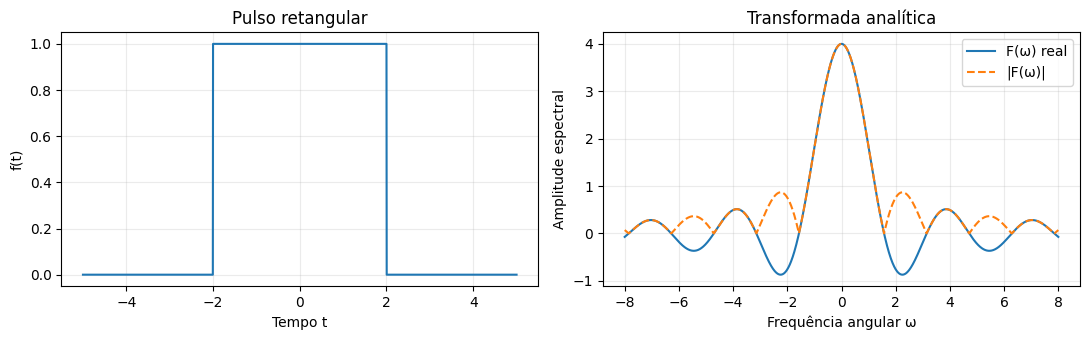

In [1]:
import numpy as np
import matplotlib.pyplot as plt

a = 2.0
t = np.linspace(-5, 5, 2001)
w = np.linspace(-8, 8, 1601)
f = (np.abs(t) <= a).astype(float)
F = 2*a*np.sinc(a*w/np.pi)  # inclui corretamente o ponto w=0
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(t, f); ax[0].set(title='Pulso retangular', xlabel='Tempo t', ylabel='f(t)')
ax[1].plot(w, F, label='F(ω) real'); ax[1].plot(w, np.abs(F), '--', label='|F(ω)|')
ax[1].set(title='Transformada analítica', xlabel='Frequência angular ω', ylabel='Amplitude espectral')
ax[1].legend()
for q in ax: q.grid(alpha=.25)
plt.tight_layout(); plt.show()
assert np.isclose(2*a*np.sinc(a*(np.pi/a)/np.pi), 0, atol=1e-12)
assert np.isclose(F[len(w)//2], 4)

**Interpretação da figura.** À esquerda há um único evento finito, sem periodicidade. À direita, a energia desse evento aparece distribuída por um contínuo de frequências; zeros ocorrem em $\omega=m\pi/a$, $m\ne0$ inteiro.

### 5. Propriedades básicas com demonstrações

Suponha $f,g\in L^1(\mathbb R)$ e constantes $c,d$.

**Linearidade.** Pela linearidade da integral:

$$\mathcal F\{cf+dg\}(\omega)=cF(\omega)+dG(\omega).$$

**Translação no tempo.** Para $h(t)=f(t-t_0)$, substitua $u=t-t_0$:

$$H(\omega)=\int f(u)e^{-i\omega(u+t_0)}du=\boxed{e^{-i\omega t_0}F(\omega)}.$$

Atrasar o pulso preserva $|F|$, mas altera sua fase linearmente em $\omega$.

**Mudança de escala.** Para $h(t)=f(bt)$, $b\ne0$, usando $u=bt$ e o módulo do jacobiano:

$$\boxed{H(\omega)=\frac1{|b|}F\!\left(\frac\omega b\right)}.$$

**Sinal real.** Se $f$ é real, o conjugado de $F(\omega)$ é

$$\overline{F(\omega)}=\int f(t)e^{i\omega t}dt=F(-\omega).$$

Portanto $|F(-\omega)|=|F(\omega)|$: magnitude espectral de sinal real é par. Isso explicará a redundância de frequências negativas na DFT.

### 6. Energia e Parseval: o que pode ser dito rigorosamente

Para $f\in L^1\cap L^2$ vale a identidade (na convenção adotada)

$$\boxed{\int_{-\infty}^{\infty}|f(t)|^2dt=\frac1{2\pi}\int_{-\infty}^{\infty}|F(\omega)|^2d\omega.}$$

Esta é a identidade de **Plancherel/Parseval**; sua prova geral depende de resultados de análise funcional e não decorre apenas das contas elementares acima. Para o pulso, o lado esquerdo vale $2a$, e a identidade implica a integral conhecida $\int_{-\infty}^{\infty}(\sin u/u)^2du=\pi$. Não confundiremos amplitude $|F|$ com densidade espectral de um processo estocástico.

### 7. Aproximação computacional de uma integral

Para uma malha temporal $t_n=t_0+n\Delta t$ num intervalo finito, uma soma de Riemann aproxima a transformada:

$$F(\omega)\approx\Delta t\sum_{n=0}^{N-1}f(t_n)e^{-i\omega t_n}.$$

Este cálculo envolve truncamento temporal e discretização; não é idêntico à transformada exata. Usaremos essa ponte para motivar a DFT na Seção 8.6.

In [2]:
# Aproximação por integração retangular amostrando os pontos médios
N = 4000
DT = 2*a/N
t_mid = -a + (np.arange(N)+0.5)*DT
freqs = np.array([0.0, np.pi/4, np.pi/2, 2.0])
F_num = DT*np.exp(-1j*freqs[:,None]*t_mid[None,:]).sum(axis=1)
F_exata = 2*a*np.sinc(a*freqs/np.pi)
print('ω:', freqs)
print('aproximada:', np.round(F_num, 6))
print('exata:', np.round(F_exata, 6))
assert np.allclose(F_num.real, F_exata, atol=3e-6)
assert np.allclose(F_num.imag, 0, atol=1e-12)

ω: [0.         0.78539816 1.57079633 2.        ]
aproximada: [ 4.      +0.j  2.546479-0.j  0.      +0.j -0.756803+0.j]
exata: [ 4.        2.546479  0.       -0.756802]


**Interpretação.** A malha aproxima a integral com precisão alta para as frequências escolhidas, mas maior $\omega$ requer amostragem temporal suficientemente fina. A aproximação não elimina fenômenos de *aliasing* nem vazamento espectral.

### 8. Transformada de sinal versus espectro de processo estocástico

A transformação $F(\omega)$ acima aplica-se a uma **função**. Já Morettin e Toloi, §14.2, pp. 357–359, definem, para um processo estacionário e sob hipótese de somabilidade adequada da autocovariância, uma densidade espectral por série de Fourier:

$$f_Z(\lambda)=\frac1{2\pi}\sum_{h=-\infty}^{\infty}\gamma(h)e^{-i\lambda h},\qquad -\pi\le\lambda\le\pi.$$

Essa $f_Z$ descreve a distribuição da **variância** do processo por frequência e **não** é simplesmente a transformada de uma trajetória aleatória tomada até tempo infinito. É por isso que distinguimos a análise determinística de sinais do estudo estatístico da densidade espectral (Módulo 9).

### 9. Limitações e cuidados

- A integral clássica exige condições de integrabilidade; senos puros em todo $\mathbb R$ não estão em $L^1$ e requerem o formalismo de distribuições para sua transformada.
- A transformada global informa frequências, mas não localiza no tempo eventos transitórios.
- Truncar uma observação equivale a multiplicá-la por uma janela; isso afeta seu espectro.
- A interpretação quantitativa depende das unidades de tempo, da normalização e da convenção de frequência angular.

### 10. Exercícios orientados (não execute as soluções antes de tentar)

1. Calcule manualmente $\mathcal F\{2f(t-3)\}$ quando $f$ é o pulso retangular de semilargura $a=1$. Explique magnitude e fase.
2. Para $f(t)=e^{-c|t|}$, $c>0$, separe a integral nos semieixos e encontre $F(\omega)=2c/(c^2+\omega^2)$. Compare seu resultado com uma quadratura numérica.
3. **Pseudocódigo:** proponha um algoritmo de soma de Riemann para estimar $F(\omega)$ em 30 frequências; discuta custo de tempo e uso de memória.
4. Explique, sem calcular integrais, por que o espectro em magnitude de qualquer função real é simétrico.
5. Pesquise no próprio capítulo 14 do livro a definição da densidade espectral e escreva duas diferenças conceituais entre $F(\omega)$ e $f_Z(\lambda)$.

### Referências

- MORETTIN, P. A.; TOLOI, C. M. C. *Análise de séries temporais: modelos lineares univariados*. 3. ed. São Paulo: Blucher, 2018. v. 1, cap. 13, §13.4; cap. 14, §§14.2 e 14.4.1. **Consulta direta às páginas indicadas.**
- As definições de transformada contínua de funções, a dedução do pulso e as propriedades elementares são **desenvolvimento matemático complementar** desta seção, não reprodução atribuída ao livro.